<a href="https://colab.research.google.com/github/seonilj/data-science-python-neuroscience/blob/main/assignments/task3a_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis with Pandas: Part A

**Dataset:** `alzheimers_disease_data.csv` (patient-level, 2,149 rows x 35 columns)


## Planned examinations

| # | Planned examination | Why I want it | Section |
|---|---|---|---|
| 1 | Load the CSV, check shape, column names, dtypes, a few rows | First impression of the data | 1 |
| 2 | Decide what one row represents, find identifier / outcome / measurements / groups | Everything else depends on the unit of observation | 2 |
| 3 | Classify every variable (numerical, binary, nominal, ordinal, date, identifier) | Decides which summary and plot is valid | 3 |
| 4 | Unique values, category counts, ranges and summary statistics | Catch strange coding and impossible values | 4, 5 |
| 5 | Missing values, duplicates, constant columns, suspicious values, unusual precision, inconsistent coding | Data-quality audit | 4 |
| 6 | Histograms and boxplots for numerical variables | Shape, spread, outliers | 5 |
| 7 | Counts and proportions for categorical variables | Balance and rare categories | 5 |
| 8 | Grouped summaries, cross-tabulations, correlation (only where it makes sense) | Look for relationships | 5 |

**Additional examinations**:
- Check that `PatientID` is unique, to confirm "one row = one patient".
- Physiological plausibility checks (blood pressure, cholesterol components).
- Consistency between a yes/no flag (`Hypertension`) and the measurement behind it (blood pressure).
- A Kolmogorov-Smirnov test against a uniform distribution, because several variables looked suspiciously flat.
- A written list of coding and unit assumptions, since the file has no documentation.

## 1. Load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

DATA_PATH = "alzheimers_disease_data.csv"
df = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2149, 35)


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryAlzheimers,CardiovascularDisease,Diabetes,Depression,HeadInjury,Hypertension,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,9.025679,0,0,1,1,0,0,142,72,242.366840,56.150897,33.682563,162.189143,21.463532,6.518877,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,7.151293,0,0,0,0,0,0,115,64,231.162595,193.407996,79.028477,294.630909,20.613267,7.118696,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,9.673574,1,0,0,0,0,0,99,116,284.181858,153.322762,69.772292,83.638324,7.356249,5.895077,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,8.392554,0,0,0,0,0,0,118,115,159.582240,65.366637,68.457491,277.577358,13.991127,8.965106,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,5.597238,0,0,0,0,0,0,94,117,237.602184,92.869700,56.874305,291.198780,13.517609,6.045039,0,0,0.014691,0,0,1,1,0,0,XXXConfid


In [ ]:
# dtypes at a glance
print(df.dtypes.value_counts())
print("\nColumns:")
print(list(df.columns))

int64      22
float64    12
object      1
Name: count, dtype: int64

Columns:
['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness', 'Diagnosis', 'DoctorInCharge']


## 2. One row information

Check if it is one row = one patient, because of `PatientID`

In [ ]:
print("Rows:", len(df), "| unique PatientID:", df["PatientID"].nunique())
print("ID range:", df["PatientID"].min(), "to", df["PatientID"].max())
print("IDs sorted and consecutive?", df["PatientID"].is_monotonic_increasing,
      "| gaps:", (df["PatientID"].diff().dropna() != 1).sum())

Rows: 2149 | unique PatientID: 2149
ID range: 4751 to 6899
IDs sorted and consecutive? True | gaps: 0


**Conclusion:** one row = one patient, with a single snapshot of measurements. There is no date or visit column, so the data are cross-sectional.

Rough roles of the columns (my interpretation):

- **Identifier:** `PatientID`
- **Outcome candidate:** `Diagnosis` (binary)
- **Demographics / grouping:** `Age`, `Gender`, `Ethnicity`, `EducationLevel`
- **Lifestyle:** `BMI`, `Smoking`, `AlcoholConsumption`, `PhysicalActivity`, `DietQuality`, `SleepQuality`
- **Medical history:** family history, cardiovascular disease, diabetes, depression, head injury, hypertension
- **Clinical measurements:** blood pressure, cholesterol values
- **Cognitive / functional scores:** `MMSE`, `FunctionalAssessment`, `ADL`
- **Reported symptoms:** memory complaints, behavioural problems, confusion, and so on
- **No information:** `DoctorInCharge`

## 3. Classify the variables

I grouped the columns in code, so later steps can reuse the lists. The `assert` at the end makes sure no column is forgotten.

In [ ]:
id_col = "PatientID"
target = "Diagnosis"
drop_cols = ["DoctorInCharge"] # checked below: one single value for everybody

continuous_cols = ["Age", "BMI", "AlcoholConsumption", "PhysicalActivity", "DietQuality",
                   "SleepQuality", "SystolicBP", "DiastolicBP", "CholesterolTotal",
                   "CholesterolLDL", "CholesterolHDL", "CholesterolTriglycerides",
                   "MMSE", "FunctionalAssessment", "ADL"]
nominal_cols = ["Ethnicity"]              # 4 codes, no natural order
ordinal_cols = ["EducationLevel"]         # 4 codes, probably increasing education

condition_cols = ["Smoking", "FamilyHistoryAlzheimers", "CardiovascularDisease",
                  "Diabetes", "Depression", "HeadInjury", "Hypertension"]
symptom_cols = ["MemoryComplaints", "BehavioralProblems", "Confusion", "Disorientation",
                "PersonalityChanges", "DifficultyCompletingTasks", "Forgetfulness"]
binary_cols = ["Gender"] + condition_cols + symptom_cols

# sanity checks: every column belongs to exactly one group, and "binary" really means 0/1
grouped = [id_col, target] + drop_cols + continuous_cols + nominal_cols + ordinal_cols + binary_cols
assert sorted(grouped) == sorted(df.columns), "some column is not classified"
assert all(df[c].isin([0, 1]).all() for c in binary_cols + [target])
print("All", len(df.columns), "columns classified; all binary columns contain only 0 and 1.")

All 35 columns classified; all binary columns contain only 0 and 1.


### Data dictionary (variables used)

The file has no documentation, so units and code meanings below are **assumptions** and I list what is uncertain.

| Variable | Type | Meaning / assumed unit | Uncertainty |
|---|---|---|---|
| `PatientID` | identifier | patient code, 4751 to 6899 | none; never used as a feature |
| `Age` | numerical (discrete) | years, 60 to 90 | none |
| `Gender` | binary | 0 / 1 | which code is male or female is not stated |
| `Ethnicity` | nominal, 4 levels | codes 0 to 3 | labels not given; no order, so it must not be treated as a number |
| `EducationLevel` | ordinal, 4 levels | codes 0 to 3, assumed increasing education | labels not given; distance between levels unknown |
| `BMI` | numerical | kg/m2, 15 to 40 | unit assumed |
| `AlcoholConsumption` | numerical | 0 to 20, assumed units per week | unit not stated |
| `PhysicalActivity` | numerical | 0 to 10, assumed hours per week | unit not stated |
| `DietQuality`, `SleepQuality` | numerical | scores (0 to 10 and 4 to 10) | how the score was built is unknown |
| `Smoking` and 6 history flags | binary | 1 = present (assumed) | "current" or "ever" not stated |
| `SystolicBP`, `DiastolicBP` | numerical | mmHg | some rows are implausible (section 4) |
| `CholesterolTotal/LDL/HDL/Triglycerides` | numerical | mg/dL (assumed) | components do not add up (section 4) |
| `MMSE` | numerical | 0 to 30, lower = worse cognition | assumed to be the Mini-Mental State Examination |
| `FunctionalAssessment`, `ADL` | numerical | 0 to 10, lower = more impaired | direction inferred from the group means (section 5) |
| 7 symptom flags | binary | 1 = symptom present | who reported it (patient or caregiver) is unknown |
| `Diagnosis` | binary | 1 = Alzheimer's diagnosis (assumed) | how the diagnosis was made is unknown |
| `DoctorInCharge` | constant text | same value in every row | no information, dropped |

## 4. Data-quality audit

In [ ]:
def audit_columns(df):
    """One row per column: dtype, missing values, number of unique values, an example."""
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "n_unique": df.nunique(),
        "example": df.iloc[0],
    })
    out["note"] = ""
    out.loc[out["n_unique"] == len(df), "note"] = "all unique (identifier or continuous)"
    out.loc[out["n_unique"] <= 1, "note"] = "constant column"
    return out

audit_columns(df)

,dtype,n_missing,n_unique,example,note
PatientID,int64,0,2149,4751,all unique (identifier or continuous)
Age,int64,0,31,73,
Gender,int64,0,2,0,
Ethnicity,int64,0,4,0,
EducationLevel,int64,0,4,2,
BMI,float64,0,2149,22.927749,all unique (identifier or continuous)
Smoking,int64,0,2,0,
AlcoholConsumption,float64,0,2149,13.297218,all unique (identifier or continuous)
PhysicalActivity,float64,0,2149,6.327112,all unique (identifier or continuous)
DietQuality,float64,0,2149,1.347214,all unique (identifier or continuous)


In [ ]:
def quality_report(df):
    """Headline counts for the audit."""
    return pd.Series({
        "rows": len(df),
        "missing cells": int(df.isna().sum().sum()),
        "duplicated rows": int(df.duplicated().sum()),
        "duplicated PatientID": int(df[id_col].duplicated().sum()),
        "constant columns": [c for c in df.columns if df[c].nunique() <= 1],
    })

quality_report(df)

,0
rows,2149
missing cells,0
duplicated rows,0
duplicated PatientID,0
constant columns,[DoctorInCharge]


No missing values and no duplicates, which is unusually clean for patient data. `DoctorInCharge` is constant, so I drop it.
Next: do the numbers make medical sense?

In [ ]:
df = df.drop(columns=drop_cols)

# range check for every continuous column
df[continuous_cols].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(2)

,min,25%,50%,75%,max,mean,std
Age,60.00,67.00,75.00,83.00,90.00,74.91,8.99
BMI,15.01,21.61,27.82,33.87,39.99,27.66,7.22
AlcoholConsumption,0.00,5.14,9.93,15.16,19.99,10.04,5.76
PhysicalActivity,0.00,2.57,4.77,7.43,9.99,4.92,2.86
DietQuality,0.01,2.46,5.08,7.56,10.00,4.99,2.91
SleepQuality,4.00,5.48,7.12,8.56,10.00,7.05,1.76
SystolicBP,90.00,112.00,134.00,157.00,179.00,134.26,25.95
DiastolicBP,60.00,74.00,91.00,105.00,119.00,89.85,17.59
CholesterolTotal,150.09,190.25,225.09,262.03,299.99,225.20,42.54
CholesterolLDL,50.23,87.20,123.34,161.73,199.97,124.34,43.37


In [ ]:
# 1) Blood pressure: diastolic should be lower than systolic
bad_bp = df["DiastolicBP"] >= df["SystolicBP"]
print(f"Rows with diastolic >= systolic BP: {bad_bp.sum()} ({bad_bp.mean():.1%})")

# 2) Cholesterol: the usual approximation is total = LDL + HDL + triglycerides / 5 (mg/dL)
approx_total = df["CholesterolLDL"] + df["CholesterolHDL"] + df["CholesterolTriglycerides"] / 5
gap = (df["CholesterolTotal"] - approx_total).abs()
print(f"Mean absolute gap between reported and approximated total cholesterol: {gap.mean():.1f} mg/dL")

# 3) Does the Hypertension flag agree with the blood pressure values?
print("\nMean blood pressure by Hypertension flag (mmHg):")
display(df.groupby("Hypertension")[["SystolicBP", "DiastolicBP"]].mean().round(1))

Rows with diastolic >= systolic BP: 186 (8.7%)
Mean absolute gap between reported and approximated total cholesterol: 55.3 mg/dL

Mean blood pressure by Hypertension flag (mmHg):


,SystolicBP,DiastolicBP
Hypertension,,
0,134.3,90.2
1,134.2,88.0


In [ ]:
# Precision: measured values (BMI, cholesterol...) with 6+ decimals are unusual
def n_decimals(s):
    """Largest number of digits after the decimal point in a float column."""
    return s.astype(str).str.split(".").str[1].str.len().max()

print("Max decimals:", {c: int(n_decimals(df[c])) for c in ["BMI", "MMSE", "ADL", "CholesterolTotal"]})

# Shape: how close are the variables to a flat (uniform) distribution?
def ks_uniform_p(s):
    """p-value of a KS test against a uniform distribution on [min, max]."""
    return stats.kstest(s, "uniform", args=(s.min(), s.max() - s.min())).pvalue

flat_check = pd.Series({c: ks_uniform_p(df[c]) for c in ["BMI", "AlcoholConsumption", "CholesterolTotal", "MMSE", "ADL"]})
print("\nKS test vs uniform (large p = consistent with a flat distribution):")
print(flat_check.round(3))

Max decimals: {'BMI': 15, 'MMSE': 16, 'ADL': 16, 'CholesterolTotal': 14}

KS test vs uniform (large p = consistent with a flat distribution):
BMI                   0.639
AlcoholConsumption    0.917
CholesterolTotal      0.388
MMSE                  0.122
ADL                   0.147
dtype: float64


**What the audit shows**

- Pandas found nothing missing, but the *values* have problems: **8.7 % of rows have diastolic >= systolic pressure**, which is not physiologically possible.
- Total cholesterol does not follow the usual relation with its components (average gap of about 55 mg/dL).
- The `Hypertension` flag has no relation to the measured blood pressure.
- Measured values carry 14 to 16 decimals (far more than any instrument gives) and many variables look flat (uniform) over their whole range.
  Real clinical data rarely look like that, so the dataset may be simulated. I cannot prove this, but I will treat results as properties of *this file*, not of real patients.

## 5. Exploring patterns

### 5.1 Numerical variables

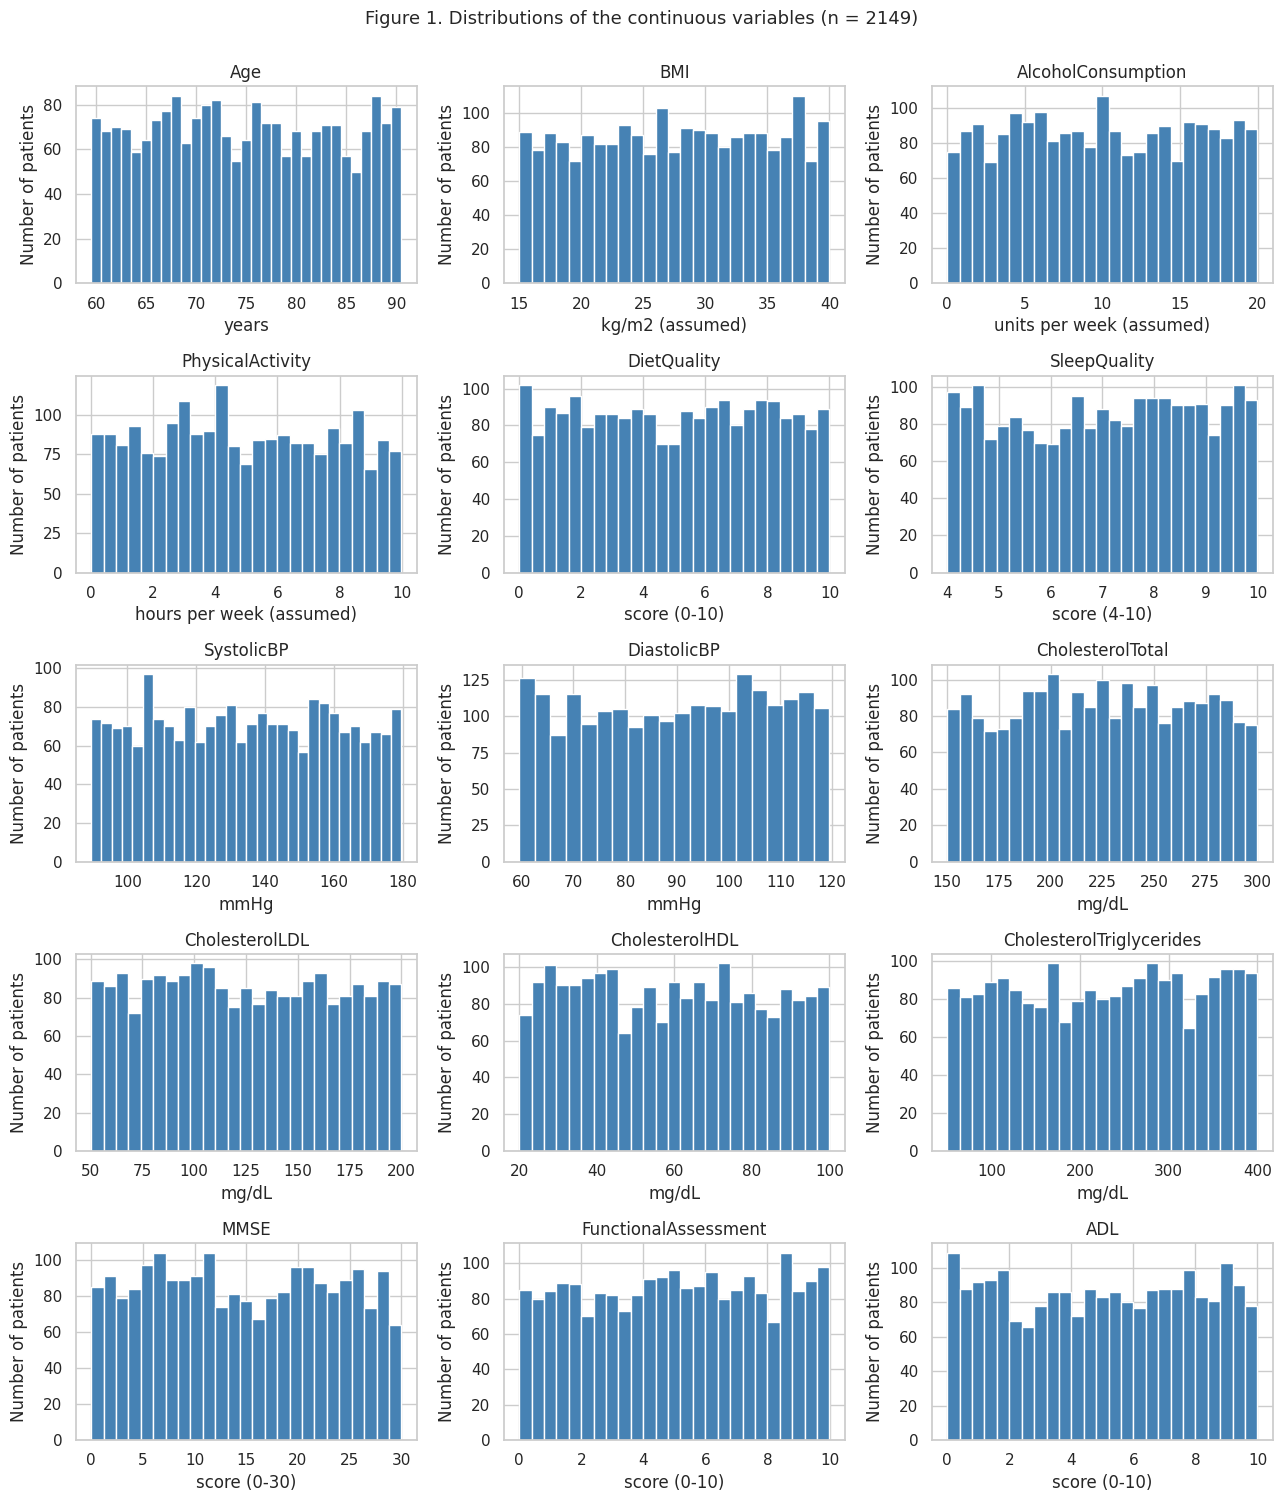

In [ ]:
UNITS = {
    "Age": "years", "BMI": "kg/m2 (assumed)", "AlcoholConsumption": "units per week (assumed)",
    "PhysicalActivity": "hours per week (assumed)", "DietQuality": "score (0-10)",
    "SleepQuality": "score (4-10)", "SystolicBP": "mmHg", "DiastolicBP": "mmHg",
    "CholesterolTotal": "mg/dL", "CholesterolLDL": "mg/dL", "CholesterolHDL": "mg/dL",
    "CholesterolTriglycerides": "mg/dL", "MMSE": "score (0-30)",
    "FunctionalAssessment": "score (0-10)", "ADL": "score (0-10)",
}

def hist_bins(s):
    """Integer columns need bin edges on half-integers, otherwise the histogram shows fake spikes."""
    if pd.api.types.is_integer_dtype(s):
        step = 3 if (s.max() - s.min() + 1) % 3 == 0 else 1
        return np.arange(s.min() - 0.5, s.max() + 1.5, step)
    return 25

fig, axes = plt.subplots(5, 3, figsize=(13, 15))
for ax, col in zip(axes.ravel(), continuous_cols):
    ax.hist(df[col], bins=hist_bins(df[col]), color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(UNITS[col])
    ax.set_ylabel("Number of patients")
fig.suptitle(f"Figure 1. Distributions of the continuous variables (n = {len(df)})", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

Almost every variable is spread evenly over its range (no bell shapes, no skew), consistent with the KS results above.
`MMSE` also has an average of only about 15 out of 30, much lower than expected in a general older population.

### 5.2 Categorical and binary variables, and class balance

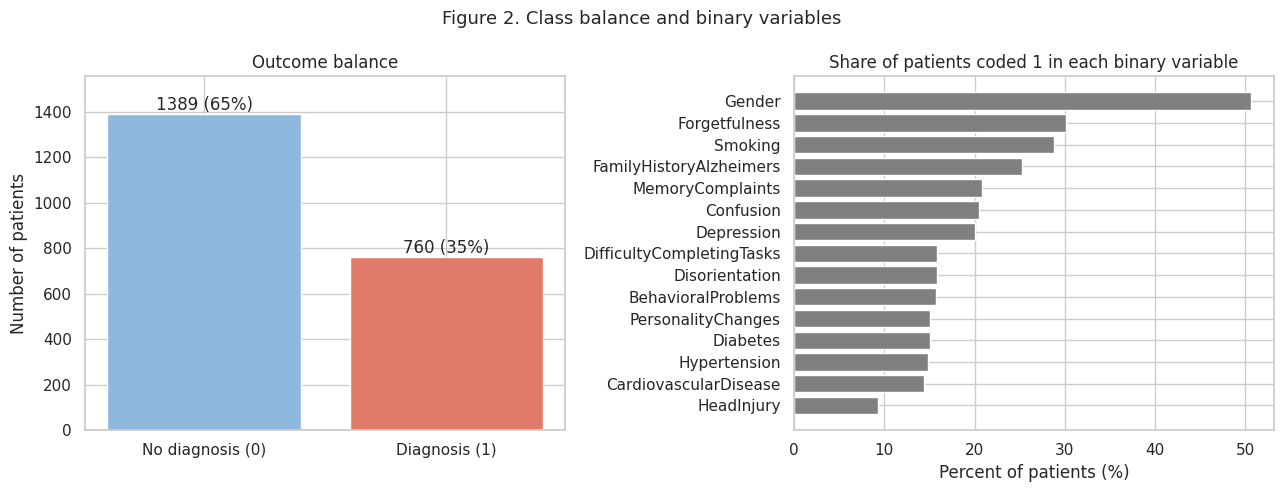

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left: outcome balance
counts = df[target].value_counts().sort_index()
axes[0].bar(["No diagnosis (0)", "Diagnosis (1)"], counts.values, color=["#8fb8de", "#e07b6a"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f"{v} ({v / len(df):.0%})", ha="center")
axes[0].set_ylim(0, counts.max() * 1.12)
axes[0].set_title("Outcome balance")
axes[0].set_ylabel("Number of patients")

# right: how common is each binary variable?
share = (df[binary_cols].mean() * 100).sort_values()
axes[1].barh(share.index, share.values, color="gray")
axes[1].set_title("Share of patients coded 1 in each binary variable")
axes[1].set_xlabel("Percent of patients (%)")

fig.suptitle("Figure 2. Class balance and binary variables", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
# category counts for the two coded (non-binary) categorical variables
for col in nominal_cols + ordinal_cols:
    print(col)
    print(df[col].value_counts().sort_index().to_frame("n").assign(share=lambda t: (t["n"] / len(df)).round(3)))
    print()

Ethnicity
              n  share
Ethnicity             
0          1278  0.595
1           454  0.211
2           206  0.096
3           211  0.098

EducationLevel
                  n  share
EducationLevel            
0               446  0.208
1               854  0.397
2               636  0.296
3               213  0.099



The outcome is moderately imbalanced (about 35 % diagnosed), so accuracy alone would be a poor metric later.
Ethnicity code 0 is the large majority (about 60 %) and codes 2 and 3 are only about 10 % each, so any subgroup analysis by ethnicity will be noisy.

### 5.3 Relationships with the diagnosis

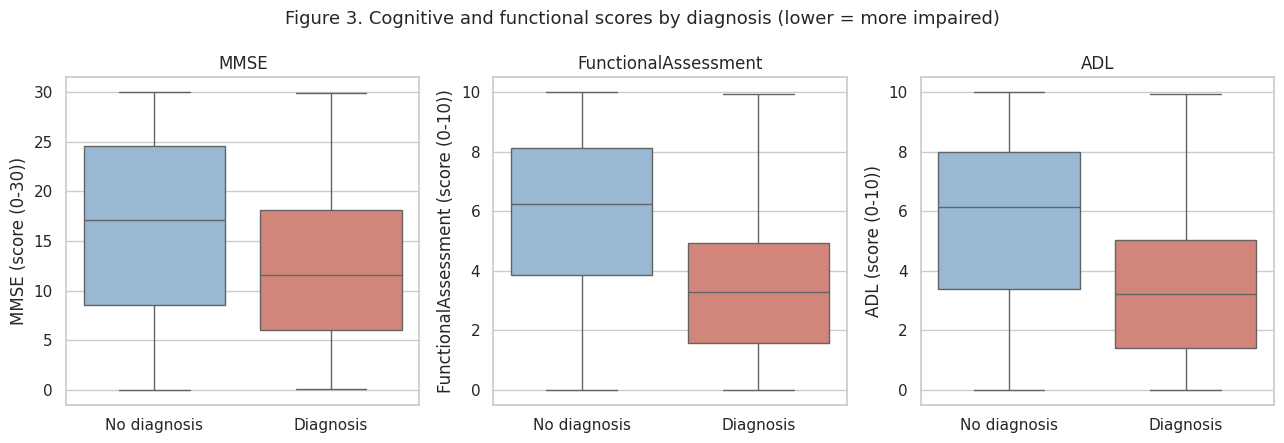

MMSE              FunctionalAssessment                ADL         \
            mean median   std                 mean median   std  mean median   
Diagnosis                                                                      
0          16.27  17.15  8.93                 5.86   6.24  2.76  5.71   6.14   
1          11.99  11.57  7.23                 3.65   3.30  2.57  3.66   3.24   

                 
            std  
Diagnosis        
0          2.83  
1          2.70

In [ ]:
score_cols = ["MMSE", "FunctionalAssessment", "ADL"]
labels = ["No diagnosis", "Diagnosis"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, col in zip(axes, score_cols):
    sns.boxplot(data=df, x=target, y=col, hue=target, palette=["#8fb8de", "#e07b6a"],
                legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels)
    ax.set_xlabel("")
    ax.set_ylabel(f"{col} ({UNITS[col]})")
    ax.set_title(col)
fig.suptitle("Figure 3. Cognitive and functional scores by diagnosis (lower = more impaired)", fontsize=13)
plt.tight_layout()
plt.show()

df.groupby(target)[score_cols].agg(["mean", "median", "std"]).round(2)

In [ ]:
def compare_groups(df, cols):
    """Mean in each diagnosis group + Mann-Whitney p-value (descriptive only, no multiple-testing correction)."""
    rows = []
    for col in cols:
        no_dx = df.loc[df[target] == 0, col]
        dx = df.loc[df[target] == 1, col]
        rows.append({"variable": col,
                     "mean_no_dx": no_dx.mean(),
                     "mean_dx": dx.mean(),
                     "p_value": stats.mannwhitneyu(no_dx, dx).pvalue})
    out = pd.DataFrame(rows).set_index("variable").sort_values("p_value")
    out["p_value"] = out["p_value"].map("{:.1e}".format)
    return out.round({"mean_no_dx": 2, "mean_dx": 2})

compare_groups(df, continuous_cols)

,mean_no_dx,mean_dx,p_value
variable,,,
FunctionalAssessment,5.86,3.65,9.0e-65
ADL,5.71,3.66,6.1e-53
MMSE,16.27,11.99,6.6e-28
SleepQuality,7.12,6.92,9.4e-03
CholesterolHDL,58.73,60.80,4.9e-02
CholesterolLDL,125.36,122.46,1.4e-01
BMI,27.52,27.91,2.2e-01
CholesterolTriglycerides,226.57,231.41,2.8e-01
SystolicBP,134.56,133.72,4.6e-01


The three scores separate the groups clearly (lower in diagnosed patients). `SleepQuality` (p about 0.01) and `CholesterolHDL` (p about 0.05)
show tiny differences that could easily be chance, since 15 variables were compared.
**Age, BMI, blood pressure and cholesterol show essentially no difference**, which is surprising, since age is the strongest known risk factor for Alzheimer's disease.

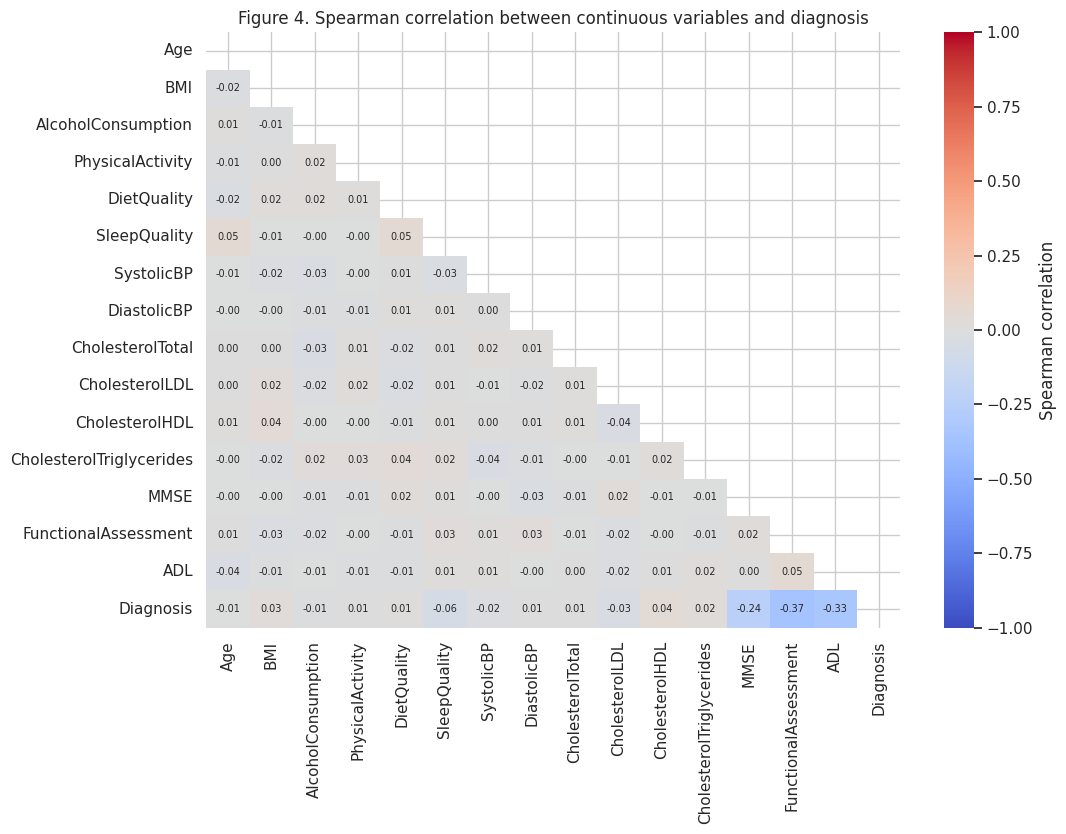

In [ ]:
# Correlation only for continuous variables (+ the binary outcome, which is fine for Spearman).
# Ethnicity is nominal and the other 0/1 columns are flags, so they are left out on purpose.
corr = df[continuous_cols + [target]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot_kws={"size": 7}, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Figure 4. Spearman correlation between continuous variables and diagnosis")
plt.tight_layout()
plt.show()

Apart from the links with `FunctionalAssessment`, `ADL` and `MMSE`, the heatmap is nearly empty. Even `MMSE`, `ADL` and `FunctionalAssessment`
are almost uncorrelated *with each other* and with `Age` (all around 0), which is unusual for real clinical scores.

In [ ]:
def prevalence_by(group):
    """Number of patients and % diagnosed within each group."""
    out = df.groupby(group)[target].agg(n="size", pct_diagnosed="mean")
    out["pct_diagnosed"] = (out["pct_diagnosed"] * 100).round(1)
    return out

groupers = {
    "Age group (years)": pd.cut(df["Age"], [59, 69, 79, 90], labels=["60-69", "70-79", "80-90"]),
    "Gender": df["Gender"],
    "Ethnicity": df["Ethnicity"],
    "EducationLevel": df["EducationLevel"],
    "MemoryComplaints": df["MemoryComplaints"],
    "BehavioralProblems": df["BehavioralProblems"],
}
for name, g in groupers.items():
    print(name)
    display(prevalence_by(g))

Age group (years)


/tmp/ipykernel_2917/4094791683.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = df.groupby(group)[target].agg(n="size", pct_diagnosed="mean")


,n,pct_diagnosed
Age,,
60-69,701,35.7
70-79,703,34.9
80-90,745,35.6


Gender


,n,pct_diagnosed
Gender,,
0,1061,36.4
1,1088,34.4


Ethnicity


... (3 outputs left out)

MemoryComplaints


,n,pct_diagnosed
MemoryComplaints,,
0,1702,27.8
1,447,64.0


BehavioralProblems


,n,pct_diagnosed
BehavioralProblems,,
0,1812,30.7
1,337,60.2


In [ ]:
# A cross-check that will matter for research question 3:
# memory complaints are strongly linked to diagnosis, but are they linked to the MMSE score?
df.groupby("MemoryComplaints")["MMSE"].agg(n="size", mean_MMSE="mean").round(2)

,n,mean_MMSE
MemoryComplaints,,
0,1702,14.72
1,447,14.88


Memory complaints are much more common among diagnosed patients (about 64 % versus 28 %), and behavioural problems too,
but the other symptom flags are not. Patients with and without memory complaints have almost the same average `MMSE`,
so self-reported complaints and the objective score seem to carry different information.

## 6. Three research questions

### Question 1: Which cognitive / functional score separates diagnosed from non-diagnosed patients best?

| Item | Answer |
|---|---|
| Research question | Which cognitive or functional score (MMSE, FunctionalAssessment or ADL) separates diagnosed from non-diagnosed patients best? |
| Rationale | Cognitive and functional tests are cheap, quick and non-invasive compared with imaging or biomarkers. Knowing which of them differs most between diagnosed and non-diagnosed patients could suggest which test is the most informative for screening, and it also helps to understand what the Diagnosis variable reflects in this dataset. |
| Variables | Comparison groups: Diagnosis (binary, 0 = not diagnosed, 1 = diagnosed, coding assumed). Scores compared: MMSE (0 to 30), FunctionalAssessment (0 to 10) and ADL (0 to 10), all numerical, with lower values assumed to mean worse function. |
| Analysis plan | First, compute the mean, median and standard deviation of each score separately for diagnosed and non-diagnosed patients to see the direction of the difference. Because the scores have different ranges, raw differences in means cannot be compared directly, so a standardized effect size (Cohen's d, the difference in group means divided by the pooled standard deviation) will be calculated for each score. Effect sizes will be preferred over p-values, since with more than two thousand patients almost any difference will be statistically significant. As the most direct measure of separation, the ROC AUC will be computed for each score on its own, with the sign of the score reversed so that lower values point towards diagnosis. Bootstrap confidence intervals for the AUC will show whether the difference between the scores is larger than random variation. The score with the highest AUC and the largest effect size will be considered the best separator. |
| Visualization | For each score, overlapping histograms or density curves for the two diagnosis groups, which show directly how much the distributions overlap. In addition, the ROC curves of all three scores on one plot, with the AUC values in the legend. |
| Limitations | The file has no documentation, so it is unknown how the diagnosis was made. If clinicians used one of these scores to make the diagnosis, a strong separation would be circular and would not be a real finding. The direction and construction of FunctionalAssessment and ADL are inferred, not documented. The data are cross-sectional, so nothing can be said about early prediction, only about separation at the time of assessment. Each score is evaluated alone, while a combination of scores might separate the groups better. Finally, if the data turn out to be synthetic, the results cannot be transferred to real clinical practice. |

### Question 2: Are lifestyle and cardiometabolic factors related to diagnosis or to cognitive performance?

| Item | Description |
|---|---|
| **Research question** | After accounting for age, gender and education, are `SleepQuality`, `DietQuality`, `PhysicalActivity`, `AlcoholConsumption`, `Smoking`, `BMI`, blood pressure, cholesterol, diabetes, hypertension and cardiovascular disease associated with `Diagnosis` or with the `MMSE` score? |
| **Rationale** | These factors are modifiable, which makes them the most useful from a prevention point of view. My exploration found almost no signal (only tiny `SleepQuality` and `CholesterolHDL` differences), so the question is also a check of whether this dataset reproduces known risk factors at all. |
| **Variables** | Outcomes: `Diagnosis` (binary) and `MMSE` (continuous, which has more statistical power). Predictors: the lifestyle, clinical and history variables listed above. Covariates: `Age`, `Gender`, `EducationLevel`. |
| **Analysis plan** | (1) Univariate comparisons by diagnosis group. (2) Multivariable logistic regression for `Diagnosis` and linear regression for `MMSE`, with standardized continuous predictors so effects are comparable. (3) Correct for multiple testing (Benjamini-Hochberg), because about 20 predictors are tested. (4) Sensitivity analysis excluding the rows with implausible blood pressure. |
| **Visualization** | Forest plot of odds ratios with 95 % confidence intervals, one row per predictor. |
| **Limitations** | Single measurement per patient, so no causal claim (reverse causality is possible: cognitive decline can change sleep or diet). Score definitions for diet, sleep and activity are unknown. The blood pressure, cholesterol and hypertension problems from section 4 weaken these predictors. No genetic or imaging data. |

### Question 3: Does cognition decline with age and is it better with more education?

| Item | Description |
|---|---|
| **Research question** | Is `MMSE` associated with `Age` and with `EducationLevel`, and are the two associations independent of each other and of `Gender`? |
| **Rationale** | Older age is the best-known risk factor for cognitive decline, and more education is widely thought to protect against it. Section 2.3 showed that the share of diagnosed patients is almost identical in all three age bands (about 35 %), and that `Age` has a Spearman correlation of about 0 with `MMSE`. Education shows a mild downward pattern in the diagnosis rate (39 % at level 0 versus 32 % at level 3). This question checks whether the dataset reproduces these two basic relationships at all. |
| **Variables** | Outcome: `MMSE` (continuous), with `Diagnosis` as a secondary outcome. Predictors: `Age` (continuous and in bands 60-69, 70-79, 80-90) and `EducationLevel` (ordinal, 0 to 3). Covariate: `Gender`. |
| **Analysis plan** | (1) Mean, median and SD of `MMSE` by age band and by education level. (2) Spearman correlation between `Age` and `MMSE`, and a Kruskal-Wallis test of `MMSE` across education levels (education is ordinal, so I do not treat the codes as exact distances). (3) Linear regression of `MMSE` on `Age`, `EducationLevel` (as categories) and `Gender`, then add an `Age` x `EducationLevel` interaction. (4) Repeat with `Diagnosis` as the outcome (logistic regression) to see if the pattern is the same. |
| **Visualization** | Scatterplot of `MMSE` against `Age` with a smoothed trend line, next to boxplots of `MMSE` by `EducationLevel`. |
| **Limitations** | Only ages 60 to 90 are present, so the age range is narrow. Cross-sectional data compare different people, not the same person over time. The meaning and spacing of the education codes are unknown. `MMSE` is normally interpreted relative to age and education in clinical practice, and here its distribution is flat (section 1.4). A simulated dataset may contain no age or education effect even though real patients would show one. |

## 7. Note on data quality and uncertainties

1. **Constant column:** `DoctorInCharge` has the same value for all patients, so it was dropped.
2. **Looks too clean:** no missing values and no duplicates at all.
3. **Impossible blood pressure:** 186 rows (8.7 %) have diastolic >= systolic. I kept them, but any analysis that uses blood pressure should be repeated without them.
4. **Inconsistent cholesterol:** total cholesterol does not match its components (mean gap about 55 mg/dL).
5. **Flags that do not match measurements:** `Hypertension = 1` patients have the same average blood pressure as the others.
6. **Signs of simulated data:** many variables are almost uniformly distributed over their range, measured values have 14 to 16 decimals,
   age is unrelated to the diagnosis, and the three clinical scores are nearly uncorrelated with each other. Conclusions apply to this dataset only.
7. **Unusual MMSE:** the scores spread evenly from 0 to 30 with a mean near 15, unlike typical community samples.
8. **Undocumented coding:** units and meanings of 0/1 codes (gender, ethnicity, education) are assumptions.
9. **Design limits:** cross-sectional, one row per patient, and the diagnosis may be partly defined by the scores that I would later use as predictors.